# End to End Regression Project - Diamond Price Prediction

This notebook shows a complete, simple machine learning workflow for regression:

- Data Loading and Understanding
- Data Cleaning (missing values, duplicates, wrong values)
- Exploratory Data Analysis
- Outliers and Feature Engineering
- Train Test Split and Preprocessing
- Feature Selection
- Model Building, Evaluation and Comparison
- Cross Validation and Hyperparameter Tuning
- Final Pipeline
- Saving Artifacts
- Streamlit Deployment Ready

---

## Complete Workflow

1. Problem Understanding
2. Data Collection
3. Data Cleaning
4. Train-Test Split
5. Data Preprocessing (Numerical + Categorical)
6. Feature Engineering and Selection
7. Model Training
8. Model Evaluation
9. Model Tuning (Hyperparameters)
10. Final Prediction / Deployment
11. Monitoring
12. Retraining

---

## Important Industry Concept

1. Split the data **before** scaling or selecting features
2. Learn everything (scaler, selected features) **only from the training data**
3. Put scaler + model in one **Pipeline**
4. Save the Pipeline and use it in the app

This avoids **data leakage**.

Install once: `pip install pandas numpy matplotlib seaborn scikit-learn xgboost streamlit`

# 1. Problem Understanding

**Goal:** predict the **price** of a diamond.

**Problem type:** Supervised Learning - **Regression** (we predict a number).

**Why useful:** fair pricing for sellers, price checking for buyers.

| Column | Meaning |
|---|---|
| carat | weight |
| cut | Fair < Good < Very Good < Premium < Ideal |
| color | D (best) to J (worst) |
| clarity | I1 (worst) to IF (best) |
| depth | total depth % |
| table | top flat face width % |
| x, y, z | length, width, depth in mm |
| price | **target** (US dollars) |

- **Independent variables (X):** carat, cut, color, clarity, depth, table, x, y, z
- **Dependent variable (y):** price

# 2. Data Collection

## Import Libraries

In [6]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import time
import pickle
import joblib

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.model_selection import KFold, StratifiedKFold, LeaveOneOut, RepeatedKFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error


sns.set_style("whitegrid")

## Load Dataset

In [13]:
# the file is a CSV (even if it is named diamonds.xls)

df = pd.read_csv(r"C:\Users\anith\Downloads\diamonds.xls")

df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [15]:
df.tail()

,carat,cut,color,clarity,depth,table,price,x,y,z
53935,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74
53939,0.75,Ideal,D,SI2,62.2,55.0,2757,5.83,5.87,3.64


In [17]:
df.sample(5, random_state=42)

,carat,cut,color,clarity,depth,table,price,x,y,z
1388,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
50052,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
41645,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
42377,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
17244,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61


## Dataset Information

In [20]:
print("Shape  :", df.shape)
print("Columns:", list(df.columns))
print("Index  :", df.index)

Shape  : (53940, 10)
Columns: ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']
Index  : RangeIndex(start=0, stop=53940, step=1)


In [22]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.1 MB


`Non-Null Count` = 53940 for every column means **no missing values**.

In [25]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [27]:
df.describe(include="object")

,cut,color,clarity
count,53940,53940,53940
unique,5,7,8
top,Ideal,G,SI1
freq,21551,11292,13065


**Problems we can already see:** `x`, `y`, `z` have minimum **0** and `y` has maximum **58.9**. We fix them in the cleaning step.

## Numerical and Categorical Columns

In [31]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()

print("Numerical  :", num_cols)
print("Categorical:", cat_cols)

Numerical  : ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
Categorical: ['cut', 'color', 'clarity']


In [33]:
df.nunique()

carat        273
cut            5
color          7
clarity        8
depth        184
table        127
price      11602
x            554
y            552
z            375
dtype: int64

In [35]:
for col in cat_cols:
    print(df[col].value_counts())
    print()

cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610
Name: count, dtype: int64

color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808
Name: count, dtype: int64

clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741
Name: count, dtype: int64



## Target Variable (price)

count    53940.000000
mean      3932.799722
std       3989.439738
min        326.000000
25%        950.000000
50%       2401.000000
75%       5324.250000
max      18823.000000
Name: price, dtype: float64
Skewness: 1.62


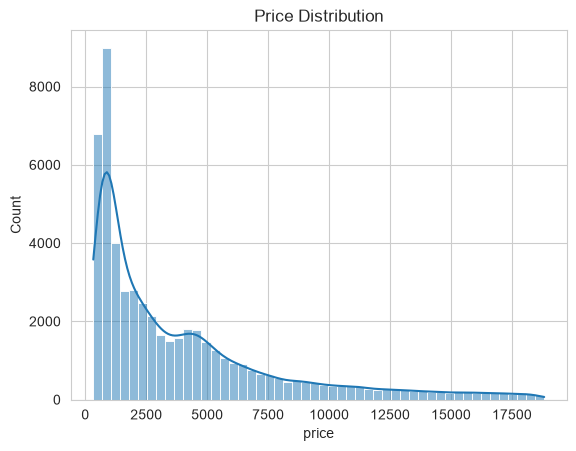

In [38]:
print(df["price"].describe())
print("Skewness:", round(df["price"].skew(), 2))

sns.histplot(df["price"], bins=50, kde=True)
plt.title("Price Distribution")
plt.show()

Most diamonds are cheap and a few are very expensive (long tail to the right).

# 3. Data Cleaning

## Missing Values

| Method | Use |
|---|---|
| Mean | numbers (no outliers) |
| Median | numbers (with outliers) |
| Mode | text columns |
| Constant | fill a fixed value like "Unknown" |
| Drop | very few missing rows |

Never fill a missing **target**. Drop that row.

In [42]:
pd.DataFrame({"missing": df.isnull().sum(), "percent": (df.isnull().mean() * 100).round(2)})

,missing,percent
carat,0,0.0
cut,0,0.0
color,0,0.0
clarity,0,0.0
depth,0,0.0
table,0,0.0
price,0,0.0
x,0,0.0
y,0,0.0
z,0,0.0


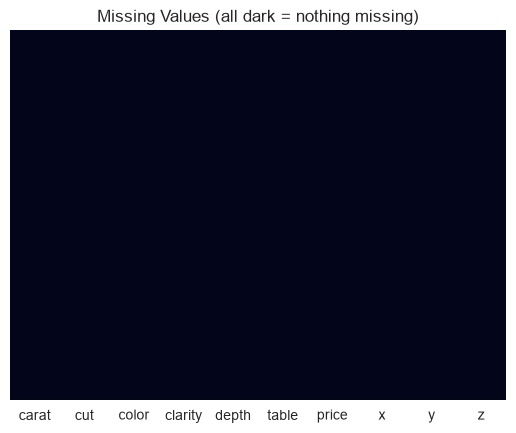

In [44]:
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values (all dark = nothing missing)")
plt.show()

No missing values. Small demo of the fill methods on fake data:

In [46]:
demo = pd.DataFrame({"carat": [0.3, 0.7, None, 1.2, 5.0], "cut": ["Good", "Ideal", None, "Ideal", "Fair"]})

print("Mean    :", demo["carat"].fillna(demo["carat"].mean()).tolist())
print("Median  :", demo["carat"].fillna(demo["carat"].median()).tolist())
print("Mode    :", demo["cut"].fillna(demo["cut"].mode()[0]).tolist())
print("Constant:", demo["cut"].fillna("Unknown").tolist())

Mean    : [0.3, 0.7, 1.8, 1.2, 5.0]
Median  : [0.3, 0.7, 0.95, 1.2, 5.0]
Mode    : ['Good', 'Ideal', 'Ideal', 'Ideal', 'Fair']
Constant: ['Good', 'Ideal', 'Unknown', 'Ideal', 'Fair']


In [49]:
df = df.dropna(subset=["price"])      # safety: never keep a missing target

## Duplicate Rows

- `keep="first"` : mark copies after the first row
- `keep="last"`  : mark copies before the last row
- `keep=False`   : mark all copies

In [52]:
print("keep first :", df.duplicated(keep="first").sum())
print("keep last  :", df.duplicated(keep="last").sum())
print("keep False :", df.duplicated(keep=False).sum())

keep first : 146
keep last  : 146
keep False : 289


In [54]:
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6)

,carat,cut,color,clarity,depth,table,price,x,y,z
43995,0.3,Good,J,VS1,63.4,57.0,394,4.23,4.26,2.69
47296,0.3,Good,J,VS1,63.4,57.0,394,4.23,4.26,2.69
34408,0.3,Ideal,G,IF,62.1,55.0,863,4.32,4.35,2.69
34422,0.3,Ideal,G,IF,62.1,55.0,863,4.32,4.35,2.69
28592,0.3,Ideal,G,VS2,63.0,55.0,675,4.31,4.29,2.71
28593,0.3,Ideal,G,VS2,63.0,55.0,675,4.31,4.29,2.71


Only 146 rows (0.27%). Copies can fall in both train and test data and make the score look better than it is, so we **remove** them.

In [57]:
df_clean = df.drop_duplicates(keep="first")

print("Before:", df.shape)
print("After :", df_clean.shape)

Before: (53940, 10)
After : (53794, 10)


## Data Validation

In [60]:
# negative values
(df_clean.select_dtypes(include="number") < 0).sum()

carat    0
depth    0
table    0
price    0
x        0
y        0
z        0
dtype: int64

In [62]:
# zero sizes
print("x, y or z = 0 :", ((df_clean["x"] == 0) | (df_clean["y"] == 0) | (df_clean["z"] == 0)).sum())

# impossible sizes (more than 20 mm)
print("size > 20 mm  :", ((df_clean["x"] > 20) | (df_clean["y"] > 20) | (df_clean["z"] > 20)).sum())

x, y or z = 0 : 19
size > 20 mm  : 3


In [64]:
# wrong category names
print(df_clean["cut"].unique())
print(df_clean["color"].unique())
print(df_clean["clarity"].unique())

<StringArray>
['Ideal', 'Premium', 'Good', 'Very Good', 'Fair']
Length: 5, dtype: str
<StringArray>
['E', 'I', 'J', 'H', 'F', 'G', 'D']
Length: 7, dtype: str
<StringArray>
['SI2', 'SI1', 'VS1', 'VS2', 'VVS2', 'VVS1', 'I1', 'IF']
Length: 8, dtype: str


In [66]:
# depth % should be close to 2*z / (x+y) * 100
depth_formula = 2 * df_clean["z"] / (df_clean["x"] + df_clean["y"]) * 100
gap = (df_clean["depth"] - depth_formula).abs()

print("Rows with depth more than 5 points away from the formula:", (gap > 5).sum())

Rows with depth more than 5 points away from the formula: 40


## Fix the Wrong Rows

In [69]:
before = len(df_clean)

df_clean = df_clean[(df_clean["x"] > 0) & (df_clean["y"] > 0) & (df_clean["z"] > 0)]
df_clean = df_clean[(df_clean["x"] < 20) & (df_clean["y"] < 20) & (df_clean["z"] < 20)]

depth_formula = 2 * df_clean["z"] / (df_clean["x"] + df_clean["y"]) * 100
df_clean = df_clean[(df_clean["depth"] - depth_formula).abs() <= 5]

df_clean = df_clean.reset_index(drop=True)

print("Rows removed:", before - len(df_clean))
print("Clean shape :", df_clean.shape)

Rows removed: 46
Clean shape : (53748, 10)


# Exploratory Data Analysis (EDA)

- **Univariate** = one column
- **Bivariate** = two columns
- **Multivariate** = many columns

In [72]:
sample = df_clean.sample(5000, random_state=42)      # smaller sample for fast scatter plots

## Histogram

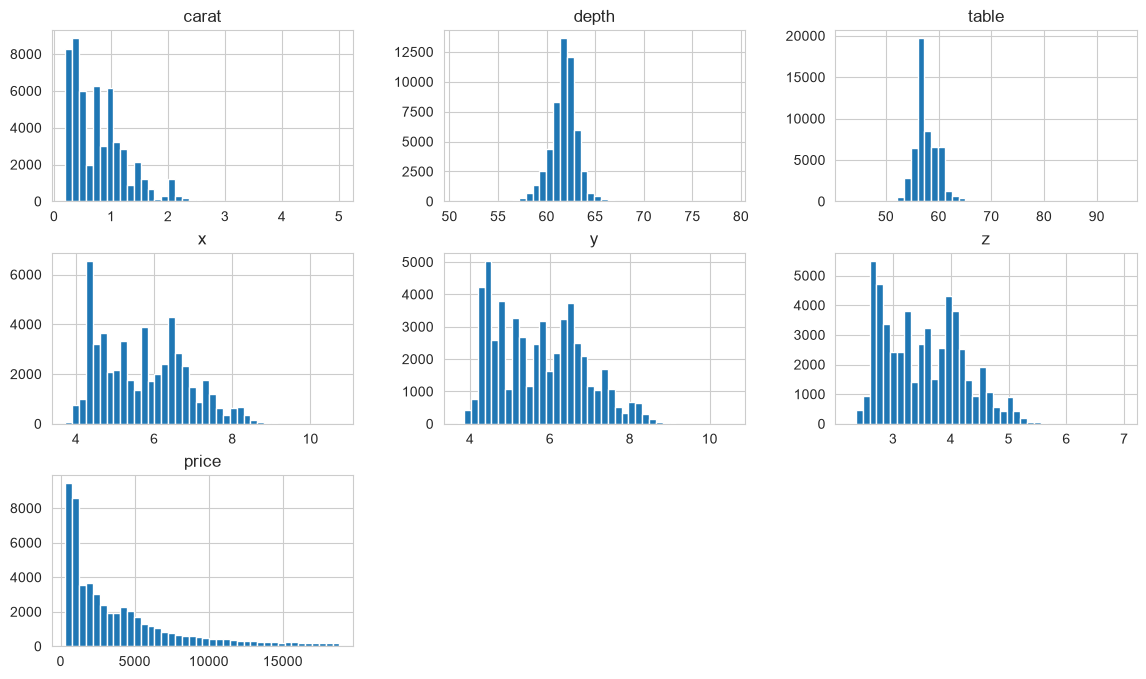

In [75]:
df_clean[["carat", "depth", "table", "x", "y", "z", "price"]].hist(bins=40, figsize=(14, 8))
plt.show()

## KDE Plot

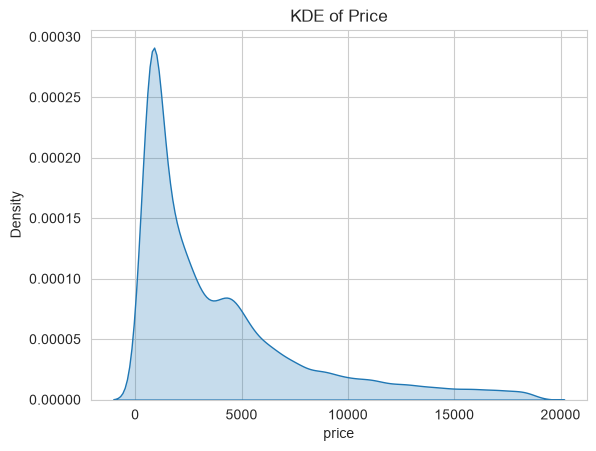

In [77]:
sns.kdeplot(df_clean["price"], fill=True)
plt.title("KDE of Price")
plt.show()

`carat` and `price` have a long right tail. `depth` and `table` are bell shaped.

## Boxplot

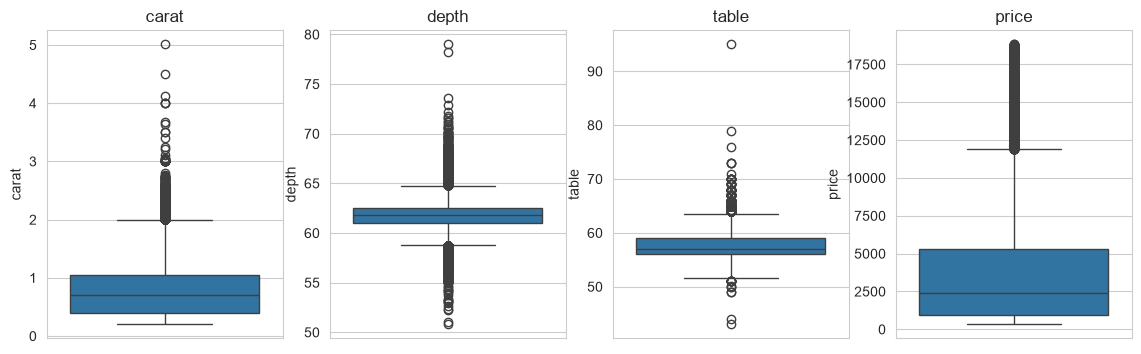

In [81]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))

for ax, col in zip(axes, ["carat", "depth", "table", "price"]):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(col)

plt.show()

## Countplot

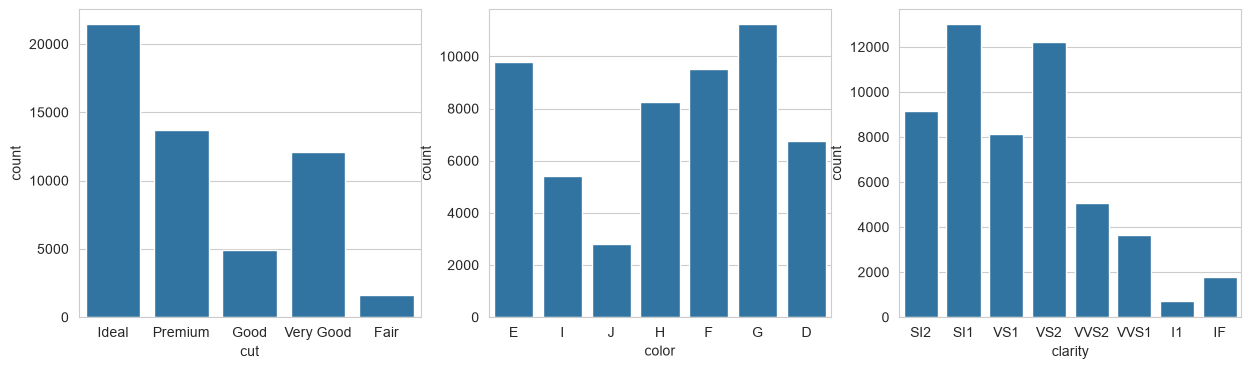

In [83]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["cut", "color", "clarity"]):
    sns.countplot(data=df_clean, x=col, ax=ax)

plt.show()

## Scatterplot (feature vs price)

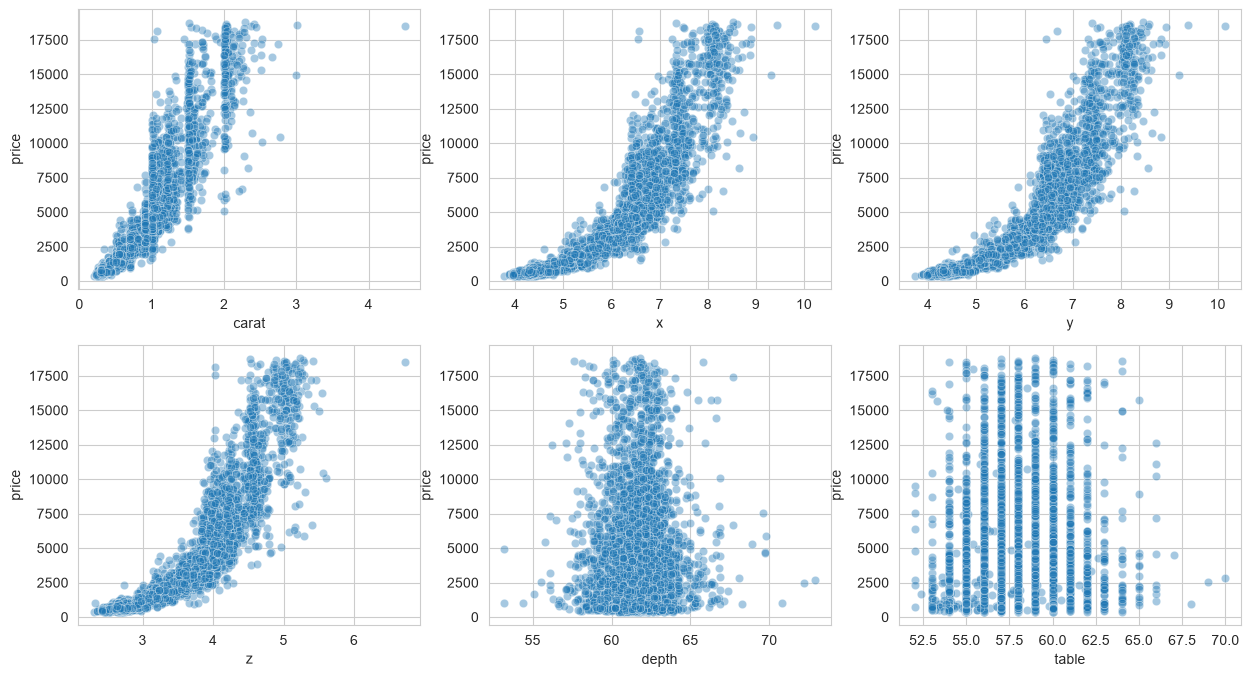

In [87]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.ravel(), ["carat", "x", "y", "z", "depth", "table"]):
    sns.scatterplot(data=sample, x=col, y="price", alpha=0.4, ax=ax)

plt.show()

`carat`, `x`, `y`, `z` have a strong **curved** relation with price. `depth` and `table` show almost no pattern.

## Barplot (average price)

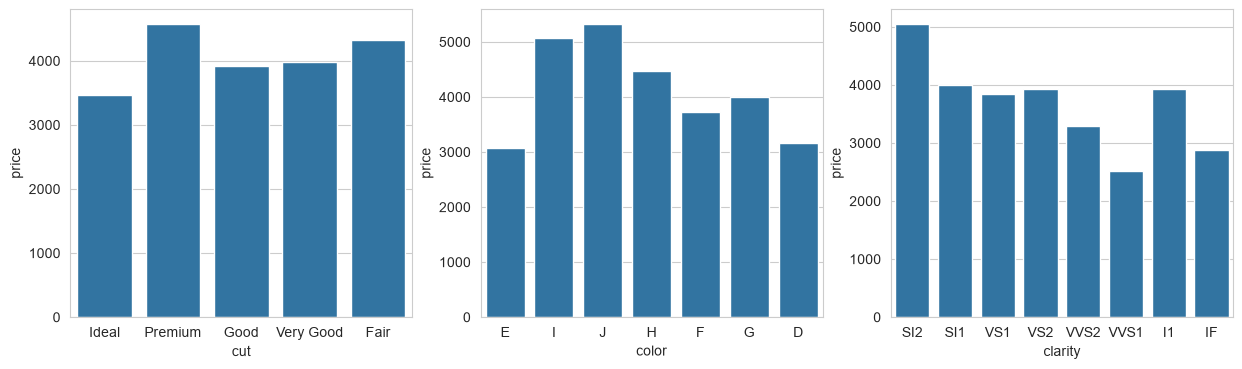

In [90]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["cut", "color", "clarity"]):
    sns.barplot(data=df_clean, x=col, y="price", errorbar=None, ax=ax)

plt.show()

In [91]:
# why does "Fair" cut look more expensive than "Ideal"?
df_clean.groupby("cut")[["carat", "price"]].mean().round(2)

,carat,price
cut,,
Fair,1.04,4330.16
Good,0.85,3916.91
Ideal,0.70,3461.78
Premium,0.89,4577.45
Very Good,0.81,3981.47


The "worse" groups have **bigger diamonds**. **Carat is the boss of the price.** Cut, color and clarity matter when diamonds have the **same carat**.

## Pairplot

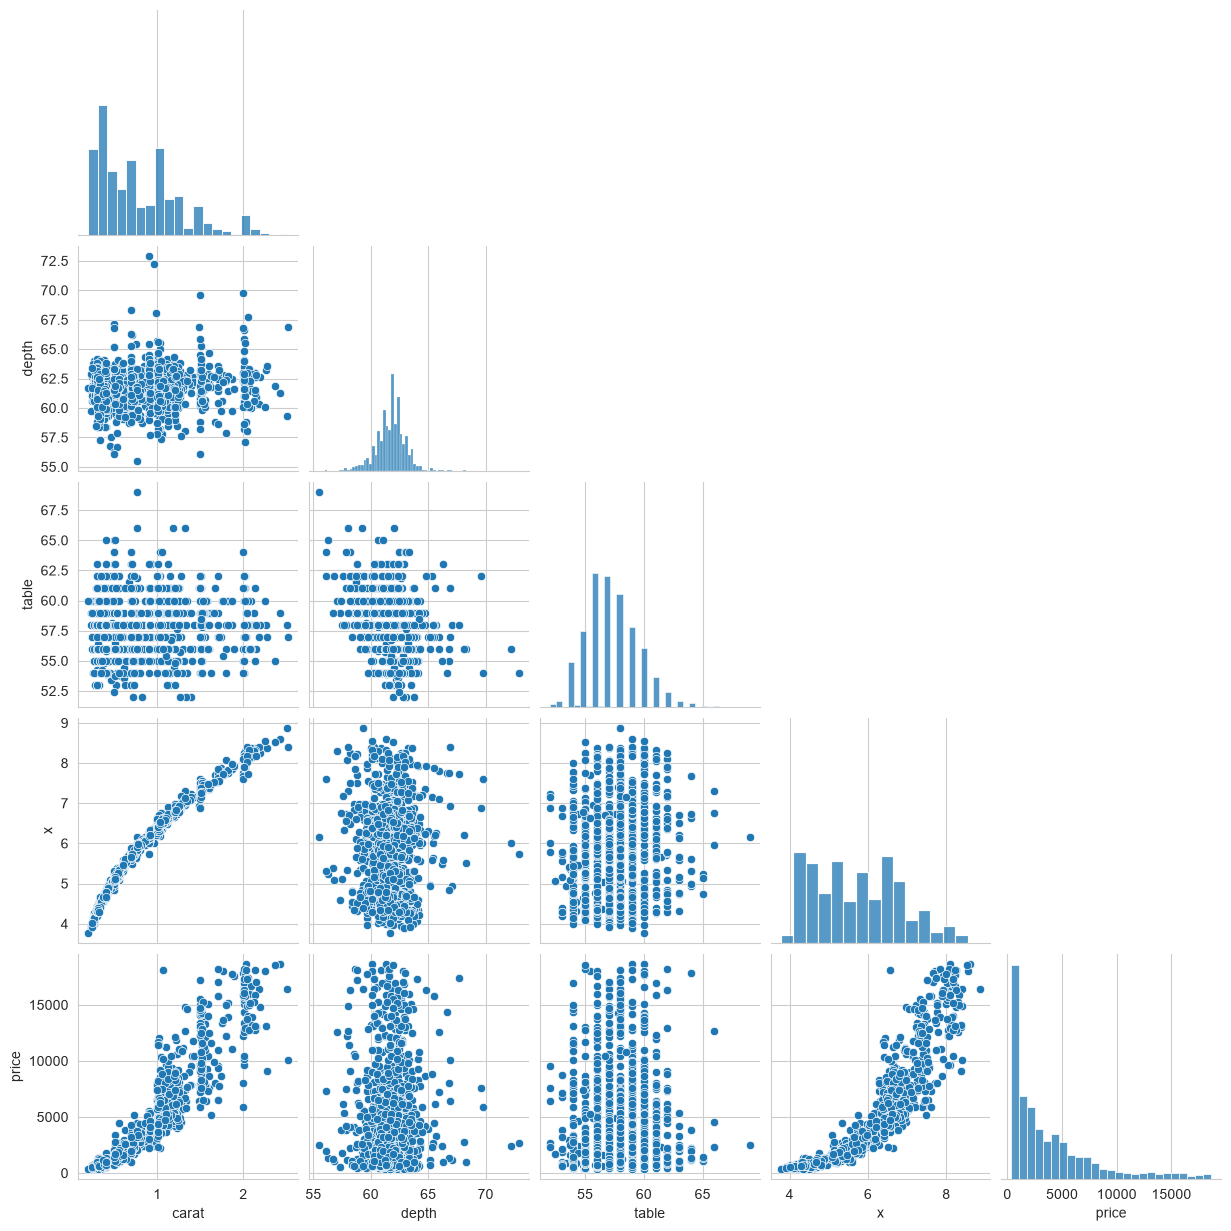

In [95]:
sns.pairplot(df_clean.sample(1500, random_state=42)[["carat", "depth", "table", "x", "price"]], corner=True)
plt.show()

## Correlation Matrix and Heatmap

In [97]:
corr = df_clean[["carat", "depth", "table", "x", "y", "z", "price"]].corr()
corr.round(2)

,carat,depth,table,x,y,z,price
carat,1.00,0.03,0.18,0.98,0.98,0.98,0.92
depth,0.03,1.00,-0.30,-0.02,-0.03,0.10,-0.01
table,0.18,-0.30,1.00,0.20,0.19,0.16,0.13
x,0.98,-0.02,0.20,1.00,1.00,0.99,0.89
y,0.98,-0.03,0.19,1.00,1.00,0.99,0.89
z,0.98,0.10,0.16,0.99,0.99,1.00,0.88
price,0.92,-0.01,0.13,0.89,0.89,0.88,1.00


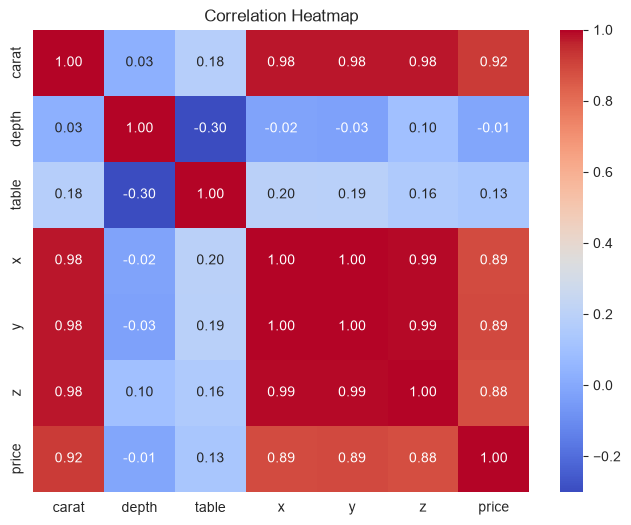

In [100]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

- `carat`, `x`, `y`, `z` are strongly related to price (0.88 to 0.92)
- `depth` is about 0 and `table` is weak
- `carat`, `x`, `y`, `z` are also strongly related to **each other** (0.98+). This is called multicollinearity.

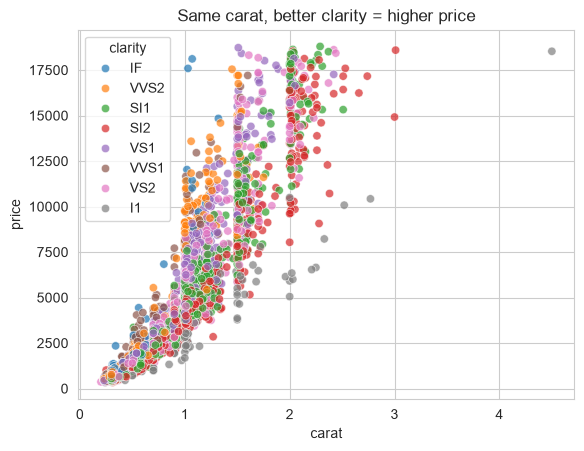

In [103]:
# multivariate: carat vs price coloured by clarity
sns.scatterplot(data=sample, x="carat", y="price", hue="clarity", alpha=0.7)
plt.title("Same carat, better clarity = higher price")
plt.show()

# Outliers

- **IQR:** outlier if below `Q1 - 1.5 x IQR` or above `Q3 + 1.5 x IQR`
- **Z-score:** outlier if `|z| > 3`
- **Boxplot:** the dots outside the whiskers

Treatment: remove / cap / transform / keep

In [106]:
for col in ["carat", "depth", "table", "x", "y", "z", "price"]:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_count = ((df_clean[col] < low) | (df_clean[col] > high)).sum()

    z = (df_clean[col] - df_clean[col].mean()) / df_clean[col].std()
    z_count = (z.abs() > 3).sum()

    print(f"{col:6s} IQR outliers: {iqr_count:5d}   Z-score outliers: {z_count:5d}")

carat  IQR outliers:  1865   Z-score outliers:   429
depth  IQR outliers:  2516   Z-score outliers:   675
table  IQR outliers:   602   Z-score outliers:   333
x      IQR outliers:    24   Z-score outliers:    35
y      IQR outliers:    20   Z-score outliers:    31
z      IQR outliers:    25   Z-score outliers:    33
price  IQR outliers:  3516   Z-score outliers:  1203


In [108]:
big = df_clean[df_clean["carat"] > 2.5]

print("Diamonds above 2.5 carat:", len(big))
print("Average price           :", round(big["price"].mean()))
big[["carat", "x", "y", "z", "price"]].head()

Diamonds above 2.5 carat: 121
Average price           : 15325


,carat,x,y,z,price
16228,3.00,9.23,9.10,5.77,6512
17140,2.72,8.46,8.43,5.76,6870
19280,3.01,9.10,8.97,5.67,8040
19287,3.00,8.93,8.84,5.97,8044
19805,2.68,9.11,9.07,5.33,8419


Big carat goes with big size and high price. These are **real diamonds**, not mistakes. We **keep** them. (Removing them would remove the expensive diamonds.)

**Decision**
- impossible values: already removed in cleaning
- genuine big diamonds: keep
- tree models are not hurt by outliers

In [111]:
# one treatment example: capping (not used in the project)
capped_carat = df_clean["carat"].clip(upper=df_clean["carat"].quantile(0.99))

print("Max carat before capping:", df_clean["carat"].max())
print("Max carat after capping :", capped_carat.max())

Max carat before capping: 5.01
Max carat after capping : 2.17


In [113]:
# one treatment example: log transform (not used in the project)
print("Skewness of price      :", round(df_clean["price"].skew(), 2))
print("Skewness of log(price) :", round(np.log1p(df_clean["price"]).skew(), 2))

Skewness of price      : 1.62
Skewness of log(price) : 0.12


# Feature Engineering

Create new helpful columns from the old ones.

| New column | Formula | Why |
|---|---|---|
| volume | x * y * z | size in 3D |
| log_carat | log(carat) | price grows in a straight line with log(carat) |
| carat_group | 0: <0.5, 1: 0.5-1, 2: 1-2, 3: 2+ | price jumps at these weights |

**Avoid target leakage:** we never use `price` to make an input column (for example "price per carat" is cheating).

In [116]:
df_clean["volume"] = df_clean["x"] * df_clean["y"] * df_clean["z"]
df_clean["log_carat"] = np.log(df_clean["carat"])
df_clean["carat_group"] = pd.cut(df_clean["carat"], bins=[0, 0.5, 1, 2, 100], labels=[0, 1, 2, 3], right=False).astype(int)

df_clean[["carat", "x", "y", "z", "volume", "log_carat", "carat_group"]].head()

,carat,x,y,z,volume,log_carat,carat_group
0,0.23,3.95,3.98,2.43,38.202030,-1.469676,0
1,0.21,3.89,3.84,2.31,34.505856,-1.560648,0
2,0.23,4.05,4.07,2.31,38.076885,-1.469676,0
3,0.29,4.20,4.23,2.63,46.724580,-1.237874,0
4,0.31,4.34,4.35,2.75,51.917250,-1.171183,0


In [118]:
print("carat     vs log(price):", round(df_clean["carat"].corr(np.log(df_clean["price"])), 3))
print("log_carat vs log(price):", round(df_clean["log_carat"].corr(np.log(df_clean["price"])), 3))

carat     vs log(price): 0.92
log_carat vs log(price): 0.966


# Categorical Encoding

| Encoder | Use |
|---|---|
| Label Encoding | target column only (A-Z order) |
| **Ordinal Encoding** | text with a natural order (**cut, color, clarity**) |
| One-Hot Encoding | text without order (city, brand) |

We give numbers in the real quality order (worst = 0).

In [121]:
cut_map = {"Fair": 0, "Good": 1, "Very Good": 2, "Premium": 3, "Ideal": 4}
color_map = {"J": 0, "I": 1, "H": 2, "G": 3, "F": 4, "E": 5, "D": 6}
clarity_map = {"I1": 0, "SI2": 1, "SI1": 2, "VS2": 3, "VS1": 4, "VVS2": 5, "VVS1": 6, "IF": 7}

df_model = df_clean.copy()
df_model["cut"] = df_model["cut"].map(cut_map)
df_model["color"] = df_model["color"].map(color_map)
df_model["clarity"] = df_model["clarity"].map(clarity_map)

df_model.head()

,carat,cut,color,clarity,depth,table,price,x,y,z,volume,log_carat,carat_group
0,0.23,4,5,1,61.5,55.0,326,3.95,3.98,2.43,38.202030,-1.469676,0
1,0.21,3,5,2,59.8,61.0,326,3.89,3.84,2.31,34.505856,-1.560648,0
2,0.23,1,5,4,56.9,65.0,327,4.05,4.07,2.31,38.076885,-1.469676,0
3,0.29,3,1,3,62.4,58.0,334,4.20,4.23,2.63,46.724580,-1.237874,0
4,0.31,1,0,1,63.3,58.0,335,4.34,4.35,2.75,51.917250,-1.171183,0


In [123]:
# other encoders, only to see how they work (not used)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

le = LabelEncoder().fit(df_clean["cut"])
print("LabelEncoder:", dict(zip(le.classes_, le.transform(le.classes_))), "<- A-Z order, wrong for quality")

print("OneHot columns:", OneHotEncoder().fit(df_clean[["color"]]).get_feature_names_out())

LabelEncoder: {'Fair': np.int64(0), 'Good': np.int64(1), 'Ideal': np.int64(2), 'Premium': np.int64(3), 'Very Good': np.int64(4)} <- A-Z order, wrong for quality
OneHot columns: ['color_D' 'color_E' 'color_F' 'color_G' 'color_H' 'color_I' 'color_J']


These maps are fixed rules (they learn nothing from the data), so it is safe to apply them before the split.

## Define Features and Target

In [127]:
X = df_model.drop("price", axis=1)
y = df_model["price"]

print("Feature Shape:", X.shape)
print("Target Shape :", y.shape)
print(list(X.columns))

Feature Shape: (53748, 12)
Target Shape : (53748,)
['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y', 'z', 'volume', 'log_carat', 'carat_group']


# 4. Train Test Split

- **80:20** is the usual split for big data. **70:30** gives a bigger test set (good for small data).
- `random_state=42` gives the same split every time.
- We split **first**, then learn the scaler and selected features **only from the training data**. This avoids data leakage.

We also keep a **validation** set (20% of the training data). We choose models and settings with it. The **test set is used only once, at the end.**

In [130]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Shape:", X_train.shape)
print("Testing Shape :", X_test.shape)

Training Shape: (42998, 12)
Testing Shape : (10750, 12)


In [132]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

print("Train      :", X_tr.shape)
print("Validation :", X_val.shape)

Train      : (34398, 12)
Validation : (8600, 12)


# 5. Data Preprocessing

## Numerical Processing - Scaling

| Scaler | Result |
|---|---|
| **StandardScaler** | mean 0, std 1 (**we use this**) |
| MinMaxScaler | values between 0 and 1 |
| RobustScaler | uses median, good for many outliers |
| MaxAbsScaler | divides by the biggest absolute value |

Scaling matters for Linear Regression, KNN and SVR. Trees do not need it.

In [135]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler, MaxAbsScaler

for name, s in [("StandardScaler", StandardScaler()), ("MinMaxScaler", MinMaxScaler()),
                ("RobustScaler", RobustScaler()), ("MaxAbsScaler", MaxAbsScaler())]:
    values = s.fit_transform(X_train[["carat"]])           # fit on TRAIN only
    print(f"{name:15s} min={values.min():6.2f}  max={values.max():6.2f}  mean={values.mean():6.2f}")

StandardScaler  min= -1.26  max=  8.87  mean=  0.00
MinMaxScaler    min=  0.00  max=  1.00  mean=  0.12
RobustScaler    min= -0.78  max=  6.73  mean=  0.15
MaxAbsScaler    min=  0.04  max=  1.00  mean=  0.16


## Numerical Processing - Transformations (for skewed data)

Log transform, PowerTransformer and QuantileTransformer make skewed data more bell shaped. Tree models do not need them, so in this simple project we **do not transform** the target. (It is an easy improvement for Linear Regression later.)

In [138]:
from sklearn.preprocessing import PowerTransformer, QuantileTransformer

price_2d = y_train.values.reshape(-1, 1)

print("Original         :", round(pd.Series(y_train.values).skew(), 2))
print("Log              :", round(pd.Series(np.log1p(y_train.values)).skew(), 2))
print("PowerTransformer :", round(pd.Series(PowerTransformer().fit_transform(price_2d).ravel()).skew(), 2))
print("Quantile         :", round(pd.Series(QuantileTransformer(output_distribution="normal").fit_transform(price_2d).ravel()).skew(), 2))

Original         : 1.61
Log              : 0.12
PowerTransformer : 0.03
Quantile         : 0.02


## Categorical Processing

Already done with ordinal encoding (cut, color, clarity). Missing values: none. If they existed, we would use the median for numbers and the most common value for text (`SimpleImputer`).

## Pipeline

We put the scaler and the model in one `Pipeline`. The scaler learns **only from the data given to `fit()`**, so there is no leakage.

In [141]:
# example: a Pipeline is scaler + model
example_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LinearRegression())
])

example_pipe.fit(X_tr, y_tr)
print("Validation R2:", round(example_pipe.score(X_val, y_val), 4))

Validation R2: 0.9155


# 6. Feature Selection

Find the columns that help most. (The notebook **Diamond_Feature_Selection_Complete** explains every method in detail.)

**We use training data only.**

## SelectKBest

In [145]:
selector = SelectKBest(score_func=f_regression, k=8)
selector.fit(X_tr, y_tr)

scores = pd.Series(selector.scores_, index=X_tr.columns).sort_values(ascending=False)
print(scores.round(0))

print("\nTop 8 Selected Features:")
print(X_tr.columns[selector.get_support()])

volume         200746.0
carat          194797.0
y              130469.0
x              128584.0
z              122538.0
log_carat       94823.0
carat_group     76254.0
color            1065.0
clarity           772.0
table             525.0
cut                84.0
depth               3.0
dtype: float64

Top 8 Selected Features:
Index(['carat', 'color', 'x', 'y', 'z', 'volume', 'log_carat', 'carat_group'], dtype='str')


## Random Forest Importance

volume         0.5164
y              0.2362
log_carat      0.0653
clarity        0.0619
carat          0.0504
x              0.0294
color          0.0292
z              0.0046
depth          0.0028
table          0.0022
cut            0.0015
carat_group    0.0001
dtype: float64


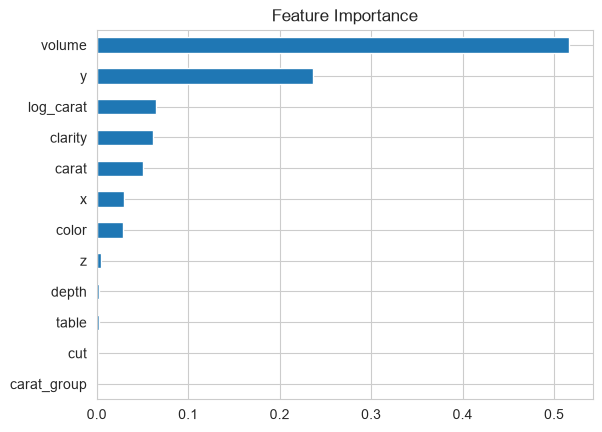

In [148]:
rf_fs = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
rf_fs.fit(X_tr.sample(10000, random_state=42), y_tr.loc[X_tr.sample(10000, random_state=42).index])

importance = pd.Series(rf_fs.feature_importances_, index=X_tr.columns).sort_values(ascending=False)
print(importance.round(4))

importance.plot(kind="barh", title="Feature Importance")
plt.gca().invert_yaxis()
plt.show()

## Do we need to drop columns? Test it

In [151]:
selected_features = X_tr.columns[selector.get_support()].tolist()
rf_test = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)

for label, cols in [("All 12 features", list(X_tr.columns)), ("Selected 8 features", selected_features)]:
    part = X_tr.sample(10000, random_state=42)
    rf_test.fit(part[cols], y_tr.loc[part.index])
    pred = rf_test.predict(X_val[cols])
    print(f"{label:20s} R2 = {r2_score(y_val, pred):.4f}   MAE = ${mean_absolute_error(y_val, pred):.0f}")

All 12 features      R2 = 0.9773   MAE = $302
Selected 8 features  R2 = 0.9074   MAE = $669


**Decision:** the 8 selected features are clearly **worse** (R2 about 0.91 against 0.98). `SelectKBest` looks at **one column at a time** and in a straight line, so it dropped `clarity`. But clarity matters a lot when it is **combined** with carat. So we keep **all 12 features**.

Lesson: a selection method is only a **suggestion**. Always test the result on validation data before you drop columns. (This also keeps the web app simple: every input box is used.)

If selection had helped, we would use `X_final = X[selected_features]` from here on, and the app would ask only for those columns.

# 7. Model Training

| Model | Idea |
|---|---|
| Linear Regression | best straight line through the data |
| Polynomial Regression | linear regression with squared and multiplied columns (a curve) |
| Decision Tree | yes/no questions, average price of a group |
| Random Forest | 100 trees, average of all |
| KNN | average price of the 5 most similar diamonds |
| SVR | curve inside a small error "tube" |
| Gradient Boosting | trees built one after another, each fixes the last one |
| XGBoost | fast, improved gradient boosting |

For each model:
1. create the model
2. `fit()` = learn from training data
3. `predict()` = guess prices of the validation data

In [157]:
models = {
    "Linear Regression": LinearRegression(),
    "Polynomial Regression": Pipeline([("poly", PolynomialFeatures(degree=2, include_bias=False)),
                                       ("linear", LinearRegression())]),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "SVR": SVR(kernel="rbf", C=1000, epsilon=10),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=4, random_state=42)
   
}
print("Models ready:", list(models.keys()))

Models ready: ['Linear Regression', 'Polynomial Regression', 'Decision Tree', 'Random Forest', 'KNN', 'SVR', 'Gradient Boosting']


# 8. Model Evaluation

| Metric | Meaning | Good |
|---|---|---|
| **MAE** | average error in dollars | small |
| **MSE** | average of squared errors | small |
| **RMSE** | square root of MSE (dollars again) | small |
| **R2** | share of price changes explained (1 = perfect) | near 1 |
| **Adjusted R2** | R2 that punishes useless columns | near 1 |
| **MAPE** | average error in % | small |

MAPE limit: it explodes for cheap diamonds and cannot be used when the real value is 0. Trust MAE, RMSE and R2 more.

In [160]:
def evaluate(y_true, y_pred, n_features=12):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - n_features - 1)
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2, "Adj_R2": adj_r2, "MAPE_%": mape}

In [162]:
# a check by hand, so there is no magic
test_pipe = Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())]).fit(X_tr, y_tr)
errors = y_val.values - test_pipe.predict(X_val)

print("MAE  by hand:", round(np.mean(np.abs(errors)), 2))
print("RMSE by hand:", round(np.sqrt(np.mean(errors ** 2)), 2))

MAE  by hand: 774.9
RMSE by hand: 1147.77


# Train and Compare All Models

We use the **validation** data to compare. SVR is slow, so it learns from 8000 rows only.

In [165]:
rows = []
trained = {}

for name, model in models.items():
    pipe = Pipeline([('scaler', StandardScaler()), ('model', model)])

    # SVR is slow on big data -> use 8000 rows
    X_fit = X_tr.sample(8000, random_state=42) if name == "SVR" else X_tr
    y_fit = y_tr.loc[X_fit.index]

    start = time.time()
    pipe.fit(X_fit, y_fit)                              # learn
    seconds = time.time() - start

    scores = evaluate(y_val, pipe.predict(X_val))       # predict + score on validation data
    scores["Train_R2"] = r2_score(y_fit, pipe.predict(X_fit))
    scores["Seconds"] = seconds
    scores["Model"] = name
    rows.append(scores)
    trained[name] = pipe

    print(f"{name:22s} R2 = {scores['R2']:.4f}   MAE = ${scores['MAE']:.0f}")

Linear Regression      R2 = 0.9155   MAE = $775
Polynomial Regression  R2 = 0.9675   MAE = $439
Decision Tree          R2 = 0.9639   MAE = $367
Random Forest          R2 = 0.9810   MAE = $271
KNN                    R2 = 0.9677   MAE = $369
SVR                    R2 = 0.9716   MAE = $315
Gradient Boosting      R2 = 0.9811   MAE = $287


Decision Tree          R2 = 0.9639   MAE = $367


Random Forest          R2 = 0.9810   MAE = $271


KNN                    R2 = 0.9677   MAE = $369


SVR                    R2 = 0.9716   MAE = $315


Gradient Boosting      R2 = 0.9811   MAE = $287


XGBoost                R2 = 0.9815   MAE = $269


# Model Comparison

In [167]:
results = pd.DataFrame(rows).set_index("Model")
results["Overfit_gap"] = results["Train_R2"] - results["R2"]
results = results[["MAE", "MSE", "RMSE", "R2", "Adj_R2", "MAPE_%", "Train_R2", "Overfit_gap", "Seconds"]].sort_values("RMSE")

results.round(4)

,MAE,MSE,RMSE,R2,Adj_R2,MAPE_%,Train_R2,Overfit_gap,Seconds
Model,,,,,,,,,
Gradient Boosting,287.0016,2.937253e+05,541.9643,0.9811,0.9811,7.9992,0.9861,0.0050,28.5092
Random Forest,270.8875,2.967389e+05,544.7375,0.9810,0.9809,6.5449,0.9974,0.0165,4.9721
SVR,314.9927,4.424706e+05,665.1846,0.9716,0.9716,8.0557,0.9750,0.0034,9.8127
KNN,368.7750,5.035291e+05,709.5978,0.9677,0.9676,9.8722,0.9803,0.0126,0.2248
Polynomial Regression,438.9337,5.059392e+05,711.2940,0.9675,0.9675,18.9478,0.9690,0.0014,0.3400
Decision Tree,366.6315,5.630397e+05,750.3597,0.9639,0.9638,8.6310,1.0000,0.0361,0.5989
Linear Regression,774.9004,1.317368e+06,1147.7664,0.9155,0.9153,42.0836,0.9113,-0.0042,0.0521


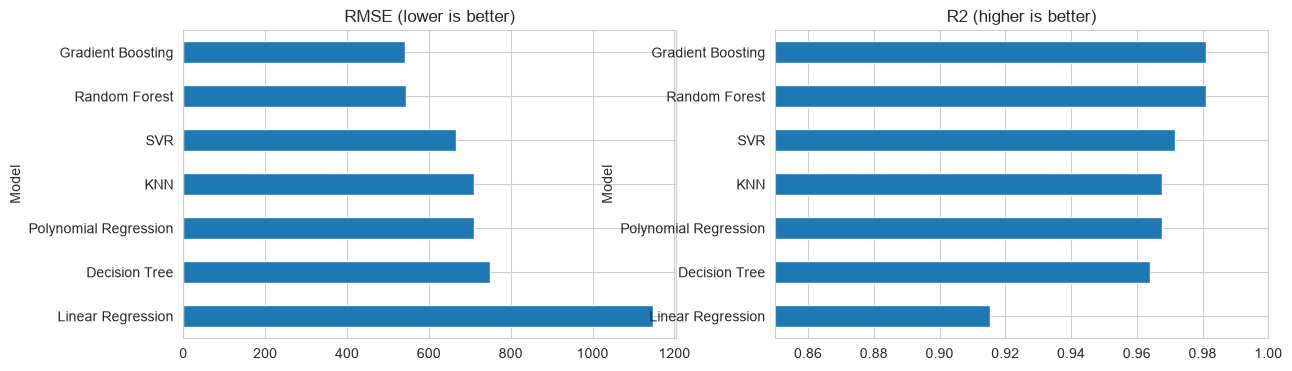

In [168]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

results["RMSE"].sort_values(ascending=False).plot(kind="barh", ax=axes[0], title="RMSE (lower is better)")
results["R2"].sort_values().plot(kind="barh", ax=axes[1], title="R2 (higher is better)", xlim=(0.85, 1))

plt.show()

**How to read**
- The best models are chosen by **validation** scores, not train scores.
- Tree based models (XGBoost, Gradient Boosting, Random Forest) are the best.
- Linear Regression is last because the price grows in a curve.
- The Decision Tree has `Train_R2` = 1.0 but lower validation R2 = **overfitting**.
- `Overfit_gap` = Train_R2 - validation R2. A big gap means overfitting.

In [173]:
best_name = results.index[0]
print("Best model:", best_name)

Best model: Gradient Boosting


## Actual vs Predicted (validation, best model)

In [176]:
best_pred = trained[best_name].predict(X_val)

compare = pd.DataFrame({"Actual": y_val.values[:8], "Predicted": best_pred[:8].round(0)})
compare["Error"] = compare["Predicted"] - compare["Actual"]
compare

,Actual,Predicted,Error
0,1362,1228.0,-134.0
1,5888,5983.0,95.0
2,854,748.0,-106.0
3,1154,1244.0,90.0
4,1624,1549.0,-75.0
5,12698,13628.0,930.0
6,803,694.0,-109.0
7,3790,4001.0,211.0


# Cross Validation

One validation set can be lucky. Cross validation tests on several parts and gives an average.

| Method | Use |
|---|---|
| **K-Fold** | standard choice |
| **Stratified K-Fold** | classification. For prices we must first cut price into groups. |
| **Leave-One-Out** | tiny data only (very slow) |
| **Repeated K-Fold** | K-Fold done several times |

We use 10,000 rows of the training data to keep it fast. The `Pipeline` is re-fitted in every fold, so there is no leakage.

In [181]:
X_cv = X_train.sample(10000, random_state=42)
y_cv = y_train.loc[X_cv.index]

cv_models = {
    "Linear Regression": Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())]),
    "Random Forest": Pipeline([('scaler', StandardScaler()), ('model', RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1))])
}

In [183]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe in cv_models.items():
    scores = cross_val_score(pipe, X_cv, y_cv, cv=kfold, scoring="r2")
    print(f"{name:18s} scores: {scores.round(4)}  mean: {scores.mean():.4f}  std: {scores.std():.4f}")

Linear Regression  scores: [0.9131 0.9201 0.913  0.9124 0.9137]  mean: 0.9144  std: 0.0028
Random Forest      scores: [0.978  0.9757 0.9766 0.9748 0.9762]  mean: 0.9763  std: 0.0011


XGBoost            scores: [0.9772 0.9764 0.9747 0.976  0.9769]  mean: 0.9762  std: 0.0009


Mean = the cross-validation score. A **small std** = stable model.

In [186]:
# Stratified K-Fold for a number target: cut price into 5 groups first
price_groups = pd.qcut(y_cv, q=5, labels=False)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_val_score(cv_models["Linear Regression"], X_cv, y_cv, cv=skf.split(X_cv, price_groups), scoring="r2")
print("Stratified scores:", scores.round(4), "mean:", scores.mean().round(4))

Stratified scores: [0.9097 0.9146 0.9188 0.9141 0.9193] mean: 0.9153


In [188]:
# Leave-One-Out: only 200 rows (one model per row!)
scores = cross_val_score(cv_models["Linear Regression"], X_cv.iloc[:200], y_cv.iloc[:200], cv=LeaveOneOut(), scoring="neg_mean_absolute_error")
print("Models trained:", len(scores), "| average error: $", round(-scores.mean(), 1))

Models trained: 200 | average error: $ 853.1


In [190]:
# Repeated K-Fold: 5 folds x 3 times = 15 scores
rkf = RepeatedKFold(n_splits=5, n_repeats=3, random_state=42)
scores = cross_val_score(cv_models["Linear Regression"], X_cv, y_cv, cv=rkf, scoring="r2")
print("Scores:", len(scores), "| mean:", scores.mean().round(4), "| std:", scores.std().round(4))

Scores: 15 | mean: 0.9149 | std: 0.0044


Cross validation agrees with the validation table: tree models beat Linear Regression, and the std is small.

# 9. Model Tuning (Hyperparameters)

- **Parameters** = learned by the model
- **Hyperparameters** = chosen by you (`max_depth`, `n_estimators`, `learning_rate`)

| Method | How |
|---|---|
| **GridSearchCV** | tries **every** combination |
| **RandomizedSearchCV** | tries some **random** combinations (faster) |

Result: `best_params_` (best settings) and `best_estimator_` (best model).

Pipeline settings are written as `model__<name>` (the step name, two underscores, the setting).

In [196]:
from sklearn.neighbors import KNeighborsRegressor

tune_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor(n_jobs=-1))
])

param_grid = {
    'model__n_neighbors': [3, 5, 7, 9],
    'model__weights': ['uniform', 'distance']
}

In [198]:
X_tune = X_tr.sample(10000, random_state=42)      # training data sample (fast)
y_tune = y_tr.loc[X_tune.index]

grid = GridSearchCV(tune_pipe, param_grid, cv=3, scoring='r2')
grid.fit(X_tune, y_tune)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(n_jobs=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__n_neighbors': [3, 5, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbo

In [199]:
print("Best Parameters:", grid.best_params_)
print("Best CV R2     :", round(grid.best_score_, 4))

Best Parameters: {'model__n_neighbors': 9, 'model__weights': 'distance'}
Best CV R2     : 0.9625


In [200]:
pd.DataFrame(grid.cv_results_)[["params", "mean_test_score", "rank_test_score"]].sort_values("rank_test_score")

,params,mean_test_score,rank_test_score
7,"{'model__n_neighbors': 9, 'model__weights': 'd...",0.962544,1
5,"{'model__n_neighbors': 7, 'model__weights': 'd...",0.962371,2
3,"{'model__n_neighbors': 5, 'model__weights': 'd...",0.961272,3
6,"{'model__n_neighbors': 9, 'model__weights': 'u...",0.961007,4
4,"{'model__n_neighbors': 7, 'model__weights': 'u...",0.960988,5
2,"{'model__n_neighbors': 5, 'model__weights': 'u...",0.960127,6
1,"{'model__n_neighbors': 3, 'model__weights': 'd...",0.958228,7
0,"{'model__n_neighbors': 3, 'model__weights': 'u...",0.957296,8


## Before and After Tuning

In [207]:
from sklearn.neighbors import KNeighborsRegressor

# 1. Make sure you use the correct key for your trained KNN model
before_pred = trained["KNN"].predict(X_val)

# 2. Build your tuned pipeline using KNeighborsRegressor
tuned_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model', KNeighborsRegressor(
        n_neighbors=grid.best_params_['model__n_neighbors'],
        weights=grid.best_params_['model__weights'],
        n_jobs=-1
    ))
])

tuned_pipe.fit(X_tr, y_tr)
after_pred = tuned_pipe.predict(X_val)

pd.DataFrame({
    "Before tuning": evaluate(y_val, before_pred), 
    "After tuning": evaluate(y_val, after_pred)
}).T.round(3)

,MAE,MSE,RMSE,R2,Adj_R2,MAPE_%
Before tuning,368.775,503529.06,709.598,0.968,0.968,9.872
After tuning,349.298,461280.03,679.176,0.970,0.970,9.700


If "After tuning" has smaller MAE and RMSE, tuning helped. For a model that is already good, the gain is small. That is normal.

## Overfitting and Underfitting

- **Underfitting:** too simple. Bad score on train **and** validation (high bias).
- **Overfitting:** memorises train data. Great train score, worse validation score (high variance).
- **Regularization:** a penalty that keeps the model simple (Ridge, Lasso, `max_depth`).
- **Learning curve:** score when we give the model more and more data.

           train_R2  val_R2
max_depth                  
1            0.6134  0.6065
2            0.8285  0.8303
3            0.8894  0.8916
4            0.9166  0.9167
6            0.9566  0.9530
8            0.9744  0.9695
10           0.9835  0.9741
12           0.9894  0.9745
15           0.9955  0.9692
20           0.9996  0.9652
30           1.0000  0.9645


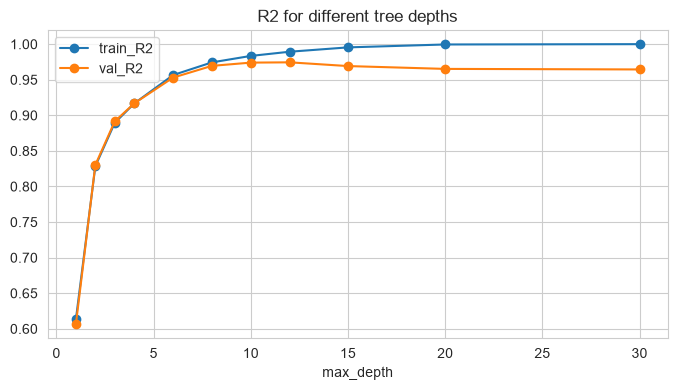

In [211]:
# tree depth: underfitting on the left, overfitting on the right
depth_rows = []

for depth in [1, 2, 3, 4, 6, 8, 10, 12, 15, 20, 30]:
    tree = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_tr, y_tr)
    depth_rows.append([depth, tree.score(X_tr, y_tr), tree.score(X_val, y_val)])

depth_table = pd.DataFrame(depth_rows, columns=["max_depth", "train_R2", "val_R2"]).set_index("max_depth")
print(depth_table.round(4))

depth_table.plot(marker="o", figsize=(8, 4), title="R2 for different tree depths")
plt.show()

- Depth 1 to 3: both scores low = **underfitting**
- Depth 8 to 12: both high and close = **good fit**
- Depth 20 to 30: train R2 near 1.0 but validation goes down = **overfitting**

In [214]:
# regularization: 454 polynomial columns and only 1500 rows = overfitting on purpose
small_X = StandardScaler().fit_transform(X_tr.sample(1500, random_state=42))
small_y = y_tr.loc[X_tr.sample(1500, random_state=42).index]

poly3 = PolynomialFeatures(degree=3, include_bias=False)
small_poly = poly3.fit_transform(small_X)
val_poly = poly3.transform(StandardScaler().fit(X_tr.sample(1500, random_state=42)).transform(X_val))

for name, model in [("No regularization", LinearRegression()), ("Ridge alpha=10", Ridge(alpha=10)),
                    ("Lasso alpha=1", Lasso(alpha=1, max_iter=5000))]:
    model.fit(small_poly, small_y)
    print(f"{name:20s} train R2 = {model.score(small_poly, small_y):.3f}   validation R2 = {model.score(val_poly, y_val):.3f}")

No regularization    train R2 = 0.992   validation R2 = -0.123
Ridge alpha=10       train R2 = 0.985   validation R2 = 0.934
Lasso alpha=1        train R2 = 0.985   validation R2 = 0.946


Without regularization the validation score is much lower than the train score. Ridge and Lasso keep the weights small and fix this.

            train_RMSE  val_RMSE
train_rows                      
500              917.0    1042.0
1000             841.0     934.0
2500             750.0     850.0
5000             686.0     799.0
10000            620.0     767.0
20000            589.0     745.0
34398            563.0     710.0


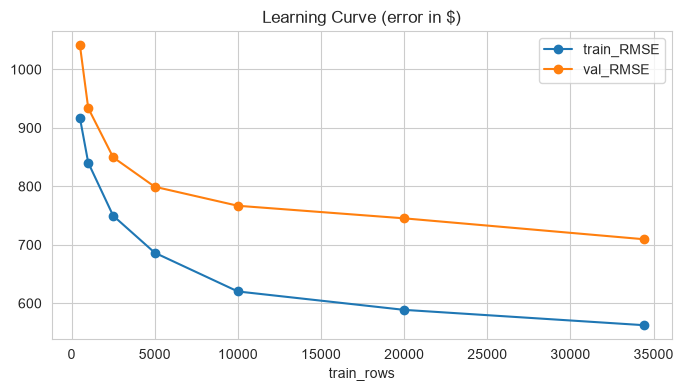

In [219]:
from sklearn.neighbors import KNeighborsRegressor

curve_rows = []

for n in [500, 1000, 2500, 5000, 10000, 20000, len(X_tr)]:
    part_X, part_y = X_tr.iloc[:n], y_tr.iloc[:n]
    
    # Using KNeighborsRegressor with a pipeline/scaler since KNN requires scaling
    m = Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=5, n_jobs=-1))
    ])
    
    m.fit(part_X, part_y)
    
    train_rmse = np.sqrt(mean_squared_error(part_y, m.predict(part_X)))
    val_rmse = np.sqrt(mean_squared_error(y_val, m.predict(X_val)))
    curve_rows.append([n, train_rmse, val_rmse])

curve = pd.DataFrame(curve_rows, columns=["train_rows", "train_RMSE", "val_RMSE"]).set_index("train_rows")
print(curve.round(0))

curve.plot(marker="o", figsize=(8, 4), title="Learning Curve (error in $)")
plt.show()

With more data the validation error goes down (about 910 dollars to about 560 dollars) and the gap between train and validation becomes smaller. The model is well fitted. More data would help only a little.

# 10. Final Industry Ready Pipeline

Rules:
1. Choose the model with the best **validation** score. Use tuned settings only if they are better.
2. Train the final pipeline on **all training data** (train + validation).
3. Look at the **test set only once**.

Notice that the pipeline expects the same 12 columns as in training.

In [225]:
from sklearn.neighbors import KNeighborsRegressor

use_tuned = evaluate(y_val, after_pred)["RMSE"] < evaluate(y_val, before_pred)["RMSE"]
print("Use tuned settings:", use_tuned)

if use_tuned:
    final_model = KNeighborsRegressor(
        n_neighbors=grid.best_params_['model__n_neighbors'],
        weights=grid.best_params_['model__weights'],
        n_jobs=-1
    )
else:
    # Default fallback settings if tuned didn't beat baseline
    final_model = KNeighborsRegressor(
        n_neighbors=5,
        weights='uniform',
        n_jobs=-1
    )

final_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', final_model)
])

final_pipeline.fit(X_train, y_train)

Use tuned settings: True


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['carat','cut','color',...,'volume','log_carat','carat_group']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## Final Model Evaluation (Test Data)

In [228]:
y_pred = final_pipeline.predict(X_test)

test_scores = evaluate(y_test, y_pred)

for name, value in test_scores.items():
    print(f"{name:8s}: {value:,.4f}")

MAE     : 329.8812
MSE     : 431,710.2185
RMSE    : 657.0466
R2      : 0.9722
Adj_R2  : 0.9722
MAPE_%  : 9.3877


The test score is close to the validation score, so the model works on new data and there is no leakage.

## Actual vs Predicted

In [231]:
result = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred.round(0)}, index=y_test.index)
result["Error"] = result["Predicted"] - result["Actual"]
result["Error_%"] = (result["Error"] / result["Actual"] * 100).round(1)

result.head(10)

,Actual,Predicted,Error,Error_%
36739,958,1033.0,75.0,7.8
53257,2675,2511.0,-164.0,-6.1
38123,384,481.0,97.0,25.3
3638,3438,3516.0,78.0,2.3
16670,610,557.0,-53.0,-8.7
25483,14402,13044.0,-1358.0,-9.4
26552,16427,16145.0,-282.0,-1.7
34125,857,1243.0,386.0,45.0
45405,1689,1739.0,50.0,3.0
36570,953,900.0,-53.0,-5.6


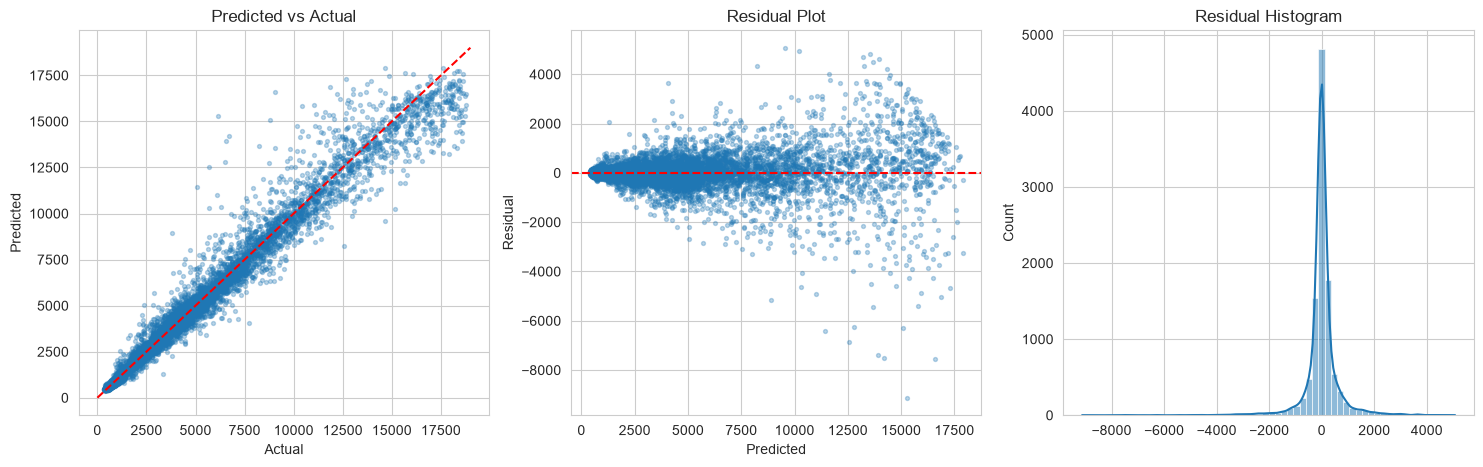

In [233]:
residuals = y_test.values - y_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(y_test, y_pred, alpha=0.3, s=8)
axes[0].plot([0, 19000], [0, 19000], "r--")
axes[0].set_title("Predicted vs Actual")
axes[0].set_xlabel("Actual")
axes[0].set_ylabel("Predicted")

axes[1].scatter(y_pred, residuals, alpha=0.3, s=8)
axes[1].axhline(0, color="r", linestyle="--")
axes[1].set_title("Residual Plot")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Residual")

sns.histplot(residuals, bins=60, kde=True, ax=axes[2])
axes[2].set_title("Residual Histogram")

plt.show()

- **Predicted vs Actual:** points near the red line = good predictions
- **Residual plot:** random cloud around 0 = no pattern missed
- **Histogram:** bell shape around 0 = no tendency to guess too high or too low

# Save Model and Artifacts

| | pickle | joblib |
|---|---|---|
| what | Python's built-in saving | made for scikit-learn / NumPy |
| good for | small objects | bigger models |

We save:
- the trained **pipeline** (scaler + model)
- the **feature columns** (exact order)
- the **maps** for cut, color and clarity

The app needs all three.

In [237]:
feature_columns = list(X_train.columns)
maps = {"cut": cut_map, "color": color_map, "clarity": clarity_map}

pickle.dump(final_pipeline, open('model.pkl', 'wb'))
pickle.dump(feature_columns, open('feature_columns.pkl', 'wb'))
pickle.dump(maps, open('maps.pkl', 'wb'))

# same model with joblib (to compare the file size)
joblib.dump(final_pipeline, 'model.joblib')

print("Artifacts Saved Successfully")
print("Feature order:", feature_columns)

Artifacts Saved Successfully
Feature order: ['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'x', 'y', 'z', 'volume', 'log_carat', 'carat_group']


# Custom Prediction

New diamonds need the **same steps as training**: new columns, text to numbers, same column order. Then the pipeline scales and predicts.

In [240]:
model = pickle.load(open('model.pkl', 'rb'))
feature_columns = pickle.load(open('feature_columns.pkl', 'rb'))
maps = pickle.load(open('maps.pkl', 'rb'))

def predict_price(carat, cut, color, clarity, depth, table, x, y, z):
    custom_data = pd.DataFrame([{
        'carat': carat,
        'cut': maps['cut'][cut],
        'color': maps['color'][color],
        'clarity': maps['clarity'][clarity],
        'depth': depth,
        'table': table,
        'x': x,
        'y': y,
        'z': z,
        'volume': x * y * z,
        'log_carat': np.log(carat),
        'carat_group': 0 if carat < 0.5 else 1 if carat < 1 else 2 if carat < 2 else 3
    }])
    custom_data = custom_data[feature_columns]
    return model.predict(custom_data)[0]

In [242]:
print("0.30 ct, Ideal, E, VS1   : $", round(predict_price(0.30, "Ideal", "E", "VS1", 61.8, 56, 4.30, 4.32, 2.67)))
print("1.00 ct, Very Good, G, SI1: $", round(predict_price(1.00, "Very Good", "G", "SI1", 62.0, 58, 6.40, 6.43, 3.98)))
print("2.00 ct, Premium, F, VS2  : $", round(predict_price(2.00, "Premium", "F", "VS2", 61.5, 59, 8.10, 8.07, 4.97)))

0.30 ct, Ideal, E, VS1   : $ 733
1.00 ct, Very Good, G, SI1: $ 4881
2.00 ct, Premium, F, VS2  : $ 16973


In [244]:
# sense check: the loaded model must give the same answers as the model in memory
print("Same predictions:", np.allclose(model.predict(X_test.head(100)), final_pipeline.predict(X_test.head(100))))

Same predictions: True
